In [19]:
import sys
from pathlib import Path

import matplotlib
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score,
                             classification_report)
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

RANDOM_STATE = 42

df = pd.read_csv(r"c:\Users\HP\Downloads\Iris.csv").drop(columns=["Id"], errors="ignore")
df["Species"] = df["Species"].str.replace("Iris-", "", regex=False)
print(f" {df}")


      SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm    Species
0              5.1           3.5            1.4           0.2     setosa
1              4.9           3.0            1.4           0.2     setosa
2              4.7           3.2            1.3           0.2     setosa
3              4.6           3.1            1.5           0.2     setosa
4              5.0           3.6            1.4           0.2     setosa
..             ...           ...            ...           ...        ...
145            6.7           3.0            5.2           2.3  virginica
146            6.3           2.5            5.0           1.9  virginica
147            6.5           3.0            5.2           2.0  virginica
148            6.2           3.4            5.4           2.3  virginica
149            5.9           3.0            5.1           1.8  virginica

[150 rows x 5 columns]


In [14]:
features = [c for c in df.columns if c != "Species"]
X, y = df[features], df["Species"]

print(f"\nShape: {df.shape}")
print(f"Missing values: {int(df.isna().sum().sum())}")
print("\nClass balance:\n", y.value_counts().to_string())
print("\nSummary statistics:\n", df.describe().round(2).to_string())



Shape: (150, 5)
Missing values: 0

Class balance:
 Species
setosa        50
versicolor    50
virginica     50

Summary statistics:
        SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm
count         150.00        150.00         150.00        150.00
mean            5.84          3.05           3.76          1.20
std             0.83          0.43           1.76          0.76
min             4.30          2.00           1.00          0.10
25%             5.10          2.80           1.60          0.30
50%             5.80          3.00           4.35          1.30
75%             6.40          3.30           5.10          1.80
max             7.90          4.40           6.90          2.50


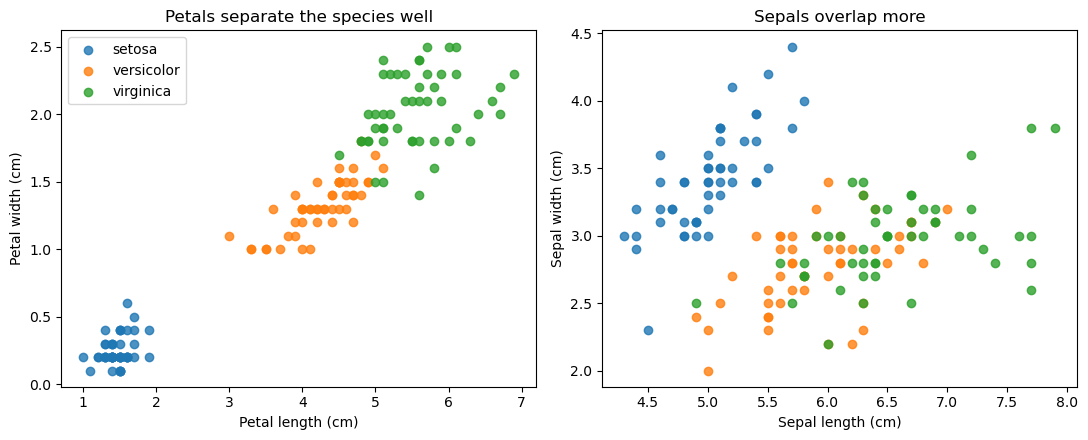

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for sp, g in df.groupby("Species"):
    axes[0].scatter(g["PetalLengthCm"], g["PetalWidthCm"], label=sp, alpha=.8)
    axes[1].scatter(g["SepalLengthCm"], g["SepalWidthCm"], label=sp, alpha=.8)
axes[0].set(xlabel="Petal length (cm)", ylabel="Petal width (cm)",
            title="Petals separate the species well")
axes[1].set(xlabel="Sepal length (cm)", ylabel="Sepal width (cm)",
            title="Sepals overlap more")
axes[0].legend()
plt.tight_layout()
plt.show()

In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print(f"\nTrain size: {len(X_train)} | Test size: {len(X_test)}")


Train size: 120 | Test size: 30


In [ ]:
# Define models to evaluate
models = {
    "Logistic Regression": make_pipeline(StandardScaler(),
                                         LogisticRegression(max_iter=500)),
    "KNN (k=5)": make_pipeline(StandardScaler(), KNeighborsClassifier(5)),
    "SVM (RBF)": make_pipeline(StandardScaler(), SVC()),
    "Decision Tree": DecisionTreeClassifier(max_depth=3,
                                            random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=200,
                                            random_state=RANDOM_STATE),
}

In [ ]:
# Evaluate models using 5-fold cross-validation on the training set
print("\n5-fold cross-validation on the TRAINING set:")
cv_results = {}
for name, model in models.items():
    scores = cross_val_score(model, X_train, y_train, cv=5)
    cv_results[name] = scores.mean()
    print(f"  {name:<20} {scores.mean():.3f} (+/- {scores.std():.3f})")

best_name = max(cv_results, key=cv_results.get)
print(f"\nBest by cross-validation: {best_name}")


5-fold cross-validation on the TRAINING set:
  Logistic Regression  0.958 (+/- 0.026)
  KNN (k=5)            0.967 (+/- 0.031)
  SVM (RBF)            0.967 (+/- 0.031)
  Decision Tree        0.933 (+/- 0.020)
  Random Forest        0.950 (+/- 0.017)

Best by cross-validation: KNN (k=5)



=== Test-set results (KNN (k=5)) ===
Accuracy: 0.933

Classification report:
               precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        10
  versicolor      0.833     1.000     0.909        10
   virginica      1.000     0.800     0.889        10

    accuracy                          0.933        30
   macro avg      0.944     0.933     0.933        30
weighted avg      0.944     0.933     0.933        30

Test accuracy of all models (for reference):
  Logistic Regression  0.933
  KNN (k=5)            0.933
  SVM (RBF)            0.967
  Decision Tree        0.967
  Random Forest        0.900


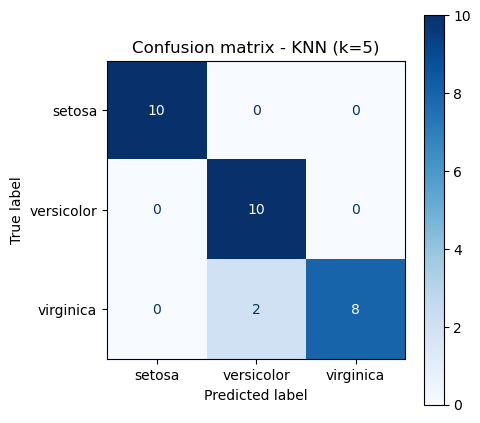

In [ ]:
# Fit the best model on the training set and evaluate on the test set
best = models[best_name].fit(X_train, y_train)
y_pred = best.predict(X_test)

print(f"\n=== Test-set results ({best_name}) ===")
print(f"Accuracy: {accuracy_score(y_test, y_pred):.3f}")
print("\nClassification report:\n",
      classification_report(y_test, y_pred, digits=3))

# Test accuracy for every model (for reference only - not used to choose)
print("Test accuracy of all models (for reference):")
for name, model in models.items():
    acc = accuracy_score(y_test, model.fit(X_train, y_train).predict(X_test))
    print(f"  {name:<20} {acc:.3f}")
best = models[best_name].fit(X_train, y_train)
y_pred = best.predict(X_test)

fig, ax = plt.subplots(figsize=(5, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap="Blues", ax=ax)
ax.set_title(f"Confusion matrix - {best_name}")
plt.tight_layout()
plt.show()


Random Forest feature importances:
 SepalWidthCm     0.018
SepalLengthCm    0.116
PetalWidthCm     0.412
PetalLengthCm    0.454


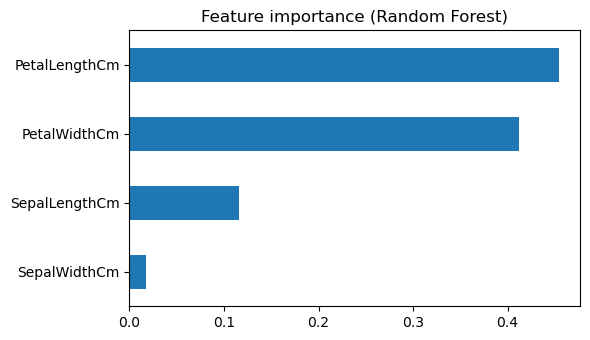

In [ ]:
# Feature importance (Random Forest)
rf = RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE)
rf.fit(X_train, y_train)
imp = pd.Series(rf.feature_importances_, index=features).sort_values()
print("\nRandom Forest feature importances:\n", imp.round(3).to_string())
imp.plot.barh(figsize=(6, 3.5), title="Feature importance (Random Forest)")
plt.tight_layout()
plt.show()

In [31]:
#Predict a new flower
sample = pd.DataFrame([[5.9, 3.0, 5.1, 1.8]], columns=features)
print(f"\nNew flower {sample.values.tolist()[0]} -> "
      f"predicted species: {best.predict(sample)[0]}")


New flower [5.9, 3.0, 5.1, 1.8] -> predicted species: virginica
